In [9]:
from google.colab import drive
drive.mount('/content/drive')

import glob, shutil, os
found = glob.glob('/content/drive/MyDrive/roman_urdu_paper_outputs*.zip')
print('found in Drive:', [(os.path.basename(f), os.path.getsize(f)) for f in found])
src = '/content/drive/MyDrive/roman_urdu_paper_outputs (2).zip'
shutil.copy(src, '/content/roman_urdu_paper_outputs (2).zip')
print('copied:', os.path.getsize('/content/roman_urdu_paper_outputs (2).zip'), 'bytes')   # should be 41924621

Mounted at /content/drive
found in Drive: [('roman_urdu_paper_outputs (1).zip', 41266550), ('roman_urdu_paper_outputs (2).zip', 41924621)]
copied: 41924621 bytes


In [10]:
import os, glob, zipfile, itertools, shutil
import numpy as np, pandas as pd
OUT = '/content/roman_urdu_paper'

def zip_ok(path):
    try:
        with zipfile.ZipFile(path) as z:
            return z.testzip() is None and any('predictions/transformers/' in n for n in z.namelist())
    except Exception:
        return False

def n_runs():
    return len(glob.glob(f'{OUT}/predictions/transformers/*.parquet'))

if n_runs() != 42:
    zips = sorted(glob.glob('/content/roman_urdu_paper_outputs*.zip'), key=os.path.getmtime)
    for z in zips:
        print(f'{os.path.basename(z)}: {os.path.getsize(z):,} bytes, complete = {zip_ok(z)}')
    good = [z for z in zips if zip_ok(z)]
    assert good, 'No complete zip found. Delete the zips, upload again with files.upload(), wait for 100% done, then rerun.'
    print('using', os.path.basename(good[-1]))
    shutil.rmtree(OUT, ignore_errors=True)          # clear any half-extracted files
    zipfile.ZipFile(good[-1]).extractall(OUT)
print('transformer runs found:', n_runs())

ANA, FIG = f'{OUT}/analysis', f'{OUT}/figures'
os.makedirs(ANA, exist_ok=True); os.makedirs(FIG, exist_ok=True)

SEEDS = [13, 42, 2026]
ORDER = ['uci', 'aimlab', 'ruwv', 'khubaib']
NAMES = {'uci': 'UCI', 'aimlab': 'Aimlab', 'ruwv': 'RUWV-NSR', 'khubaib': 'Khubaib01'}
MODEL_NAMES = {'tfidf_word_lr': 'Word TF-IDF', 'tfidf_char_lr': 'Char TF-IDF', 'mbert': 'mBERT', 'xlmr': 'XLM-R'}
TRACKS = {'3class': (['uci', 'ruwv', 'khubaib'], ['neg', 'neu', 'pos']),
          'binary': (['uci', 'aimlab', 'ruwv', 'khubaib'], ['neg', 'pos'])}

base = pd.read_parquet(f'{OUT}/predictions/baseline_predictions.parquet')
trf = pd.concat([pd.read_parquet(f) for f in sorted(glob.glob(f'{OUT}/predictions/transformers/*.parquet'))],
                ignore_index=True)
preds = pd.concat([base, trf], ignore_index=True)
print(preds.groupby(['track', 'model'])[['source', 'seed']].nunique())
assert len(trf.groupby(['track', 'model', 'source', 'seed'])) == 42, 'Expected 42 transformer runs in the zip.'

roman_urdu_paper_outputs (2).zip: 41,924,621 bytes, complete = True
using roman_urdu_paper_outputs (2).zip
transformer runs found: 42
                      source  seed
track  model                      
3class mbert               3     3
       tfidf_char_lr       3     3
       tfidf_word_lr       3     3
       xlmr                3     3
binary mbert               4     3
       tfidf_char_lr       4     3
       tfidf_word_lr       4     3
       xlmr                4     3


## 2. Label agreement between corpora (RQ3)
For every pair of corpora: how many sentences they share, how often their labels agree, and Cohen's kappa.

In [11]:
from sklearn.metrics import cohen_kappa_score
ov = pd.read_csv(f'{OUT}/overlaps/exact_overlaps.csv', keep_default_na=False)
rows = []
for (a, b), g in ov.groupby(['corpus_a', 'corpus_b']):
    rows.append({'corpus_a': a, 'corpus_b': b, 'shared': len(g),
                 'agreement_%': round(100 * (g['label_a'] == g['label_b']).mean(), 1),
                 'cohen_kappa': round(cohen_kappa_score(g['label_a'], g['label_b']), 3)})
agreement = pd.DataFrame(rows).sort_values('shared', ascending=False).reset_index(drop=True)
agreement.to_csv(f'{ANA}/label_agreement.csv', index=False)
print(agreement.to_string(index=False))

for a, b in [('uci', 'khubaib'), ('aimlab', 'khubaib')]:
    g = ov[(ov.corpus_a == a) & (ov.corpus_b == b)]
    ct = pd.crosstab(g['label_a'].rename(f'{NAMES[a]} label'), g['label_b'].rename(f'{NAMES[b]} label'))
    ct.to_csv(f'{ANA}/label_crosstab_{a}_{b}.csv')
    print(f'\n{NAMES[a]} vs {NAMES[b]} labels on the same {len(g):,} sentences:\n{ct}')

corpus_a corpus_b  shared  agreement_%  cohen_kappa
  aimlab  khubaib   15884         72.8        0.591
     uci  khubaib   15433         83.7        0.755
     uci   aimlab    5245        100.0        0.974
     uci     ruwv     861         97.6        0.951
    ruwv  khubaib     788         90.5        0.817
  aimlab     ruwv      27         51.9        0.100

UCI vs Khubaib01 labels on the same 15,433 sentences:
Khubaib01 label   neg   neu   pos
UCI label                        
neg              4047   202   320
neu               678  4279   785
pos               288   250  4584

Aimlab vs Khubaib01 labels on the same 15,884 sentences:
Khubaib01 label   neg   neu   pos
Aimlab label                     
neg              4372   352   546
neu               754  3179  1041
pos              1177   447  4016


## 3. Do models learn their training corpus's labelling convention? (RQ3)
Some test sentences of an earlier corpus also appear, with their own label, in a later corpus.
On exactly those sentences, each model's accuracy is measured against **both** label sets.
If a model trained on corpus B agrees more with B's labels than with the test corpus's labels,
part of its "cross-corpus error" is disagreement between the corpora, not model failure.

In [12]:
norm_of = {}
for c in ORDER:
    t = pd.read_csv(f'{OUT}/splits/{c}_test.csv', keep_default_na=False)
    norm_of[c] = dict(zip(t['text'], t['norm']))

rows = []
for (a, b), g in ov.groupby(['corpus_a', 'corpus_b']):
    other = dict(zip(g['norm'], g['label_b']))
    for track, (corpora, classes) in TRACKS.items():
        if a not in corpora:
            continue
        p = preds[(preds.track == track) & (preds.target == a)].copy()
        p['label_other'] = p['text'].map(norm_of[a]).map(other)
        p = p[p['label_other'].isin(classes)]
        if p.empty:
            continue
        for (model, src), q in p.groupby(['model', 'source']):
            per_seed = q.groupby('seed').apply(
                lambda s: pd.Series({'acc_vs_test_labels': (s['pred'] == s['label']).mean(),
                                     'acc_vs_other_labels': (s['pred'] == s['label_other']).mean()}))
            rows.append({'shared_pair': f'{NAMES[a]}-{NAMES[b]}', 'test_corpus': NAMES[a],
                         'other_labels_from': NAMES[b], 'track': track, 'model': MODEL_NAMES[model],
                         'trained_on': NAMES[src], 'n_sentences': q['seed'].value_counts().iloc[0],
                         'labels_agree_%': round(100 * (q['label'] == q['label_other']).mean(), 1),
                         'acc_vs_test_labels': round(per_seed['acc_vs_test_labels'].mean(), 3),
                         'acc_vs_other_labels': round(per_seed['acc_vs_other_labels'].mean(), 3)})
convention = pd.DataFrame(rows)
convention.to_csv(f'{ANA}/model_vs_both_label_sets.csv', index=False)
print(convention[(convention.track == '3class') & (convention.shared_pair == 'UCI-Khubaib01')].to_string(index=False))

/tmp/ipykernel_5388/698784097.py:18: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  per_seed = q.groupby('seed').apply(
/tmp/ipykernel_5388/698784097.py:18: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  per_seed = q.groupby('seed').apply(
/tmp/ipykernel_5388/698784097.py:18: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pa

  shared_pair test_corpus other_labels_from  track       model trained_on  n_sentences  labels_agree_%  acc_vs_test_labels  acc_vs_other_labels
UCI-Khubaib01         UCI         Khubaib01 3class       mBERT  Khubaib01         1555            84.0               0.547                0.591
UCI-Khubaib01         UCI         Khubaib01 3class       mBERT   RUWV-NSR         1555            84.0               0.541                0.553
UCI-Khubaib01         UCI         Khubaib01 3class       mBERT        UCI         1555            84.0               0.694                0.701
UCI-Khubaib01         UCI         Khubaib01 3class Char TF-IDF  Khubaib01         1555            84.0               0.577                0.618
UCI-Khubaib01         UCI         Khubaib01 3class Char TF-IDF   RUWV-NSR         1555            84.0               0.624                0.622
UCI-Khubaib01         UCI         Khubaib01 3class Char TF-IDF        UCI         1555            84.0               0.712              

/tmp/ipykernel_5388/698784097.py:18: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  per_seed = q.groupby('seed').apply(
/tmp/ipykernel_5388/698784097.py:18: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  per_seed = q.groupby('seed').apply(
/tmp/ipykernel_5388/698784097.py:18: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pa

## 4. Paired bootstrap: is one model significantly better than another on the same test set?
Same test sentences, both models' predictions resampled together (1,000 times), averaged over the 3 seeds.
`diff` = macro-F1 of model_b − model_a. p-values are Holm-corrected within each family
(one track × one model pair × same-corpus or cross-corpus), e.g. the 6 cross-corpus Char-vs-XLM-R tests in 3-class.

In [13]:
def macro_f1_fast(y, p, k):
    cm = np.bincount(y * k + p, minlength=k * k).reshape(k, k)
    tp = np.diag(cm); fp = cm.sum(0) - tp; fn = cm.sum(1) - tp
    denom = 2 * tp + fp + fn
    return np.where(denom > 0, 2 * tp / np.maximum(denom, 1), 0).mean()

def arrays(track, model, src, tgt):
    classes = TRACKS[track][1]; cid = {c: i for i, c in enumerate(classes)}
    g = preds[(preds.track == track) & (preds.model == model) & (preds.source == src) & (preds.target == tgt)]
    g = g.sort_values(['seed', 'row'])
    y = g[g.seed == SEEDS[0]]['label'].map(cid).values
    P = np.stack([g[g.seed == s]['pred'].map(cid).values for s in SEEDS])
    return y, P

def holm(p):
    p = np.asarray(p); order = np.argsort(p); adj = np.empty_like(p, dtype=float); running = 0
    for rank, i in enumerate(order):
        running = max(running, (len(p) - rank) * p[i]); adj[i] = min(1.0, running)
    return adj

B = 5000
rng = np.random.default_rng(0)
COMPARISONS = [('tfidf_char_lr', 'xlmr'), ('tfidf_char_lr', 'mbert'), ('mbert', 'xlmr'), ('tfidf_word_lr', 'tfidf_char_lr')]
sig_rows, ci_rows = [], []
for track, (corpora, classes) in TRACKS.items():
    k = len(classes)
    for src, tgt in itertools.product(corpora, corpora):
        cache = {m: arrays(track, m, src, tgt) for m in MODEL_NAMES}
        y = cache['xlmr'][0]
        for m, (ym, _) in cache.items():
            assert np.array_equal(ym, y), f'test rows do not line up for {m} {track} {src}->{tgt}'
        boot = {m: np.empty(B) for m in cache}
        for b in range(B):
            i = rng.integers(0, len(y), len(y))
            for m, (_, P) in cache.items():
                boot[m][b] = np.mean([macro_f1_fast(y[i], P[s][i], k) for s in range(len(SEEDS))])
        point = {m: np.mean([macro_f1_fast(y, p, k) for p in P]) for m, (_, P) in cache.items()}
        for m in MODEL_NAMES:
            lo, hi = np.percentile(boot[m], [2.5, 97.5])
            ci_rows.append({'track': track, 'model': m, 'source': src, 'target': tgt,
                            'macro_f1': round(point[m], 4), 'ci_low': round(lo, 4), 'ci_high': round(hi, 4)})
        for ma, mb in COMPARISONS:
            d = boot[mb] - boot[ma]
            p = min(1.0, 2 * min((d <= 0).mean(), (d >= 0).mean()))
            sig_rows.append({'track': track, 'source': src, 'target': tgt,
                             'cross_corpus': src != tgt, 'model_a': ma, 'model_b': mb,
                             'diff': round(point[mb] - point[ma], 4),
                             'ci_low': round(np.percentile(d, 2.5), 4), 'ci_high': round(np.percentile(d, 97.5), 4),
                             'p_raw': max(p, 1 / (B + 1))})
        print(f'  {track} {src} -> {tgt} done')

model_ci = pd.DataFrame(ci_rows); model_ci.to_csv(f'{ANA}/macro_f1_with_ci.csv', index=False)
sig = pd.DataFrame(sig_rows)
sig['p_holm'] = np.nan
for _, g in sig.groupby(['track', 'model_a', 'model_b', 'cross_corpus']):
    sig.loc[g.index, 'p_holm'] = holm(g['p_raw'].values)
sig['significant_0.05'] = sig['p_holm'] < 0.05
sig.to_csv(f'{ANA}/paired_bootstrap_tests.csv', index=False)
view = sig[(sig.cross_corpus) & (sig.model_a == 'tfidf_char_lr') & (sig.model_b == 'xlmr')]
print('\nXLM-R minus Char TF-IDF on cross-corpus transfers:')
print(view[['track', 'source', 'target', 'diff', 'ci_low', 'ci_high', 'p_holm', 'significant_0.05']].to_string(index=False))

  3class uci -> uci done
  3class uci -> ruwv done
  3class uci -> khubaib done
  3class ruwv -> uci done
  3class ruwv -> ruwv done
  3class ruwv -> khubaib done
  3class khubaib -> uci done
  3class khubaib -> ruwv done
  3class khubaib -> khubaib done
  binary uci -> uci done
  binary uci -> aimlab done
  binary uci -> ruwv done
  binary uci -> khubaib done
  binary aimlab -> uci done
  binary aimlab -> aimlab done
  binary aimlab -> ruwv done
  binary aimlab -> khubaib done
  binary ruwv -> uci done
  binary ruwv -> aimlab done
  binary ruwv -> ruwv done
  binary ruwv -> khubaib done
  binary khubaib -> uci done
  binary khubaib -> aimlab done
  binary khubaib -> ruwv done
  binary khubaib -> khubaib done

XLM-R minus Char TF-IDF on cross-corpus transfers:
 track  source  target    diff  ci_low  ci_high  p_holm  significant_0.05
3class     uci    ruwv -0.0337 -0.0535  -0.0136  0.0024              True
3class     uci khubaib  0.0518  0.0402   0.0636  0.0012              True
3class 

## 5. Figures (saved as PNG, 300 dpi, in `roman_urdu_paper/figures`)

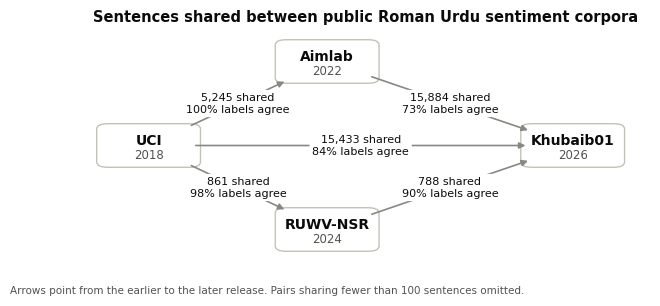

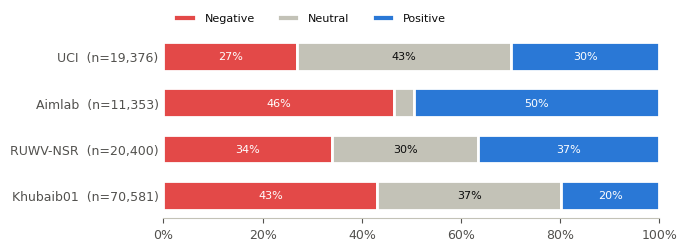

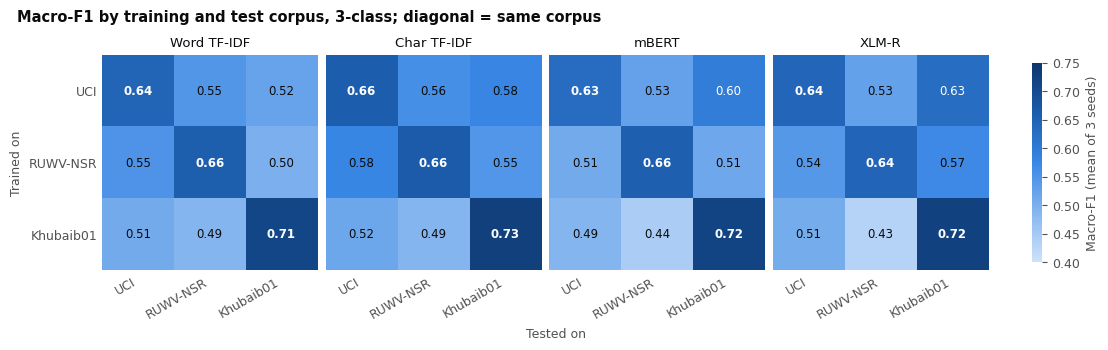

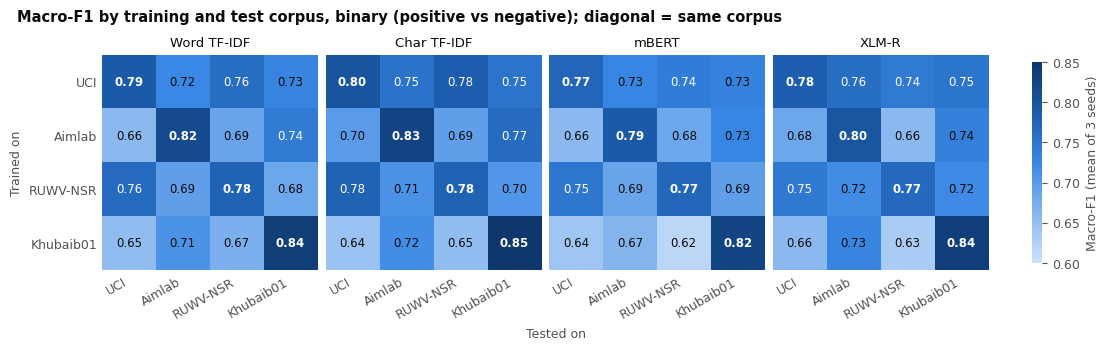

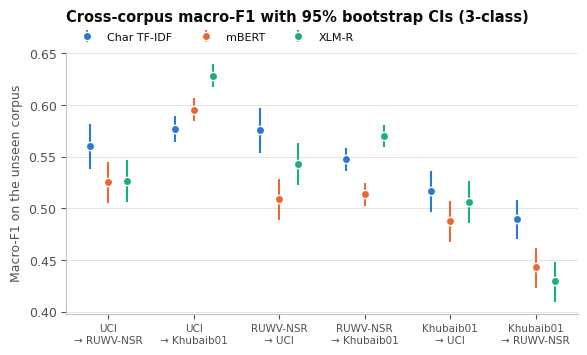

In [16]:
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import FancyBboxPatch

INK, INK2, MUTED, GRID, AXIS = '#0b0b0b', '#52514e', '#898781', '#e1e0d9', '#c3c2b7'
NEG, NEU, POS = '#e34948', '#c3c2b7', '#2a78d6'          # diverging: red / neutral gray / blue
SERIES = {'tfidf_char_lr': '#2a78d6', 'mbert': '#eb6834', 'xlmr': '#1baf7a'}   # categorical slots 1-3
BLUES = LinearSegmentedColormap.from_list('blues', ['#cde2fb', '#86b6ef', '#3987e5', '#1c5cab', '#0d366b'])
plt.rcParams.update({'font.size': 9, 'axes.edgecolor': AXIS, 'axes.labelcolor': INK2, 'xtick.color': INK2,
                     'ytick.color': INK2, 'text.color': INK, 'axes.spines.top': False, 'axes.spines.right': False,
                     'figure.facecolor': 'white', 'axes.facecolor': 'white', 'savefig.dpi': 300,
                     'savefig.bbox': 'tight'})

# --- Figure 1: dataset lineage (shared sentences and label agreement), boxes placed by release year
pos = {'uci': (0.10, 0.5), 'aimlab': (0.42, 0.82), 'ruwv': (0.42, 0.18), 'khubaib': (0.86, 0.5)}
year = {'uci': 2018, 'aimlab': 2022, 'ruwv': 2024, 'khubaib': 2026}
fig, ax = plt.subplots(figsize=(7.2, 3.0)); ax.set_axis_off(); ax.set_xlim(0, 1); ax.set_ylim(0.06, 0.94)
for c, (x, yy) in pos.items():
    ax.add_patch(FancyBboxPatch((x - 0.085, yy - 0.075), 0.17, 0.15, boxstyle='round,pad=0.008,rounding_size=0.02',
                                fc='white', ec=AXIS, lw=1))
    ax.text(x, yy + 0.02, NAMES[c], ha='center', va='center', fontsize=10, fontweight='bold', color=INK)
    ax.text(x, yy - 0.035, str(year[c]), ha='center', va='center', fontsize=8.5, color=INK2)
for _, r in agreement[agreement.shared >= 100].iterrows():
    a, b = r.corpus_a, r.corpus_b
    (x1, y1), (x2, y2) = pos[a], pos[b]
    ax.annotate('', xy=(x2, y2), xytext=(x1, y1),
                arrowprops=dict(arrowstyle='-|>', color=MUTED, lw=1.2, shrinkA=34, shrinkB=34))
    mx, my = (x1 + x2) / 2, (y1 + y2) / 2
    ax.text(mx, my, f"{int(r.shared):,} shared\n{r['agreement_%']:.0f}% labels agree", ha='center', va='center',
            fontsize=8, color=INK, bbox=dict(boxstyle='round,pad=0.25', fc='white', ec='none'))
ax.set_title('Sentences shared between public Roman Urdu sentiment corpora', loc='left', fontsize=10.5,
             color=INK, fontweight='bold')
fig.text(0.01, 0.0, 'Arrows point from the earlier to the later release. Pairs sharing fewer than 100 sentences omitted.',
         fontsize=7.5, color=INK2)
fig.savefig(f'{FIG}/fig1_dataset_lineage.png'); plt.show()

# --- Figure 2: class balance of the four final corpora (100% stacked bars)
cs = pd.read_csv(f'{OUT}/results/corpus_summary.csv').set_index('corpus').loc[ORDER]
share = cs[['neg', 'neu', 'pos']].div(cs[['neg', 'neu', 'pos']].sum(1), axis=0)
fig, ax = plt.subplots(figsize=(6.4, 2.4))
left = np.zeros(len(share))
for col, colour, label in [('neg', NEG, 'Negative'), ('neu', NEU, 'Neutral'), ('pos', POS, 'Positive')]:
    ax.barh(range(len(share)), share[col], left=left, color=colour, edgecolor='white', linewidth=2,
            height=0.62, label=label)
    for i, (v, l0) in enumerate(zip(share[col], left)):
        if v >= 0.07:
            ax.text(l0 + v / 2, i, f'{v:.0%}', ha='center', va='center', fontsize=8,
                    color=INK if col == 'neu' else 'white')
    left += share[col].values
ax.set_yticks(range(len(share)))
ax.set_yticklabels([f"{NAMES[c]}  (n={int(cs.loc[c, 'final']):,})" for c in ORDER])
ax.invert_yaxis(); ax.set_xlim(0, 1); ax.xaxis.set_major_formatter(lambda v, _: f'{v:.0%}')
ax.tick_params(axis='y', length=0); ax.spines['left'].set_visible(False)
ax.legend(ncol=3, frameon=False, loc='lower left', bbox_to_anchor=(0, 1.0), fontsize=8)
fig.savefig(f'{FIG}/fig2_class_balance.png'); plt.show()

# --- Figure 3: macro-F1 matrices (train on row, test on column), one panel per model, per track
res = pd.concat([pd.read_csv(f'{OUT}/results/baseline_results.csv'),
                 pd.read_csv(f'{OUT}/results/transformer_results.csv')], ignore_index=True)
mean_f1 = res.groupby(['track', 'model', 'source', 'target'])['macro_f1'].mean()
for track, (corpora, classes) in TRACKS.items():
    vals = mean_f1.loc[track]
    vmin, vmax = np.floor(vals.min() * 20) / 20, np.ceil(vals.max() * 20) / 20
    fig, axes = plt.subplots(1, 4, figsize=(11, 3.1), constrained_layout=True)
    for ax, model in zip(axes, MODEL_NAMES):
        M = np.array([[vals.loc[(model, s, t)] for t in corpora] for s in corpora])
        im = ax.imshow(M, cmap=BLUES, vmin=vmin, vmax=vmax)
        for i in range(len(corpora)):
            for j in range(len(corpora)):
                shade = (M[i, j] - vmin) / (vmax - vmin)
                ax.text(j, i, f'{M[i, j]:.2f}', ha='center', va='center', fontsize=8.5,
                        fontweight='bold' if i == j else 'normal', color='white' if shade > 0.55 else INK)
        ax.set_xticks(range(len(corpora))); ax.set_xticklabels([NAMES[c] for c in corpora], rotation=30, ha='right')
        ax.set_yticks(range(len(corpora))); ax.set_yticklabels([NAMES[c] for c in corpora] if model == 'tfidf_word_lr' else [])
        ax.set_title(MODEL_NAMES[model], fontsize=9.5, color=INK)
        for s in ax.spines.values(): s.set_visible(False)
        ax.tick_params(length=0)
    axes[0].set_ylabel('Trained on'); fig.supxlabel('Tested on', fontsize=9, color=INK2)
    cb = fig.colorbar(im, ax=axes, shrink=0.85); cb.outline.set_visible(False); cb.set_label('Macro-F1 (mean of 3 seeds)')
    label = '3-class' if track == '3class' else 'binary (positive vs negative)'
    fig.suptitle(f'Macro-F1 by training and test corpus, {label}; diagonal = same corpus', x=0.01, y=1.08, ha='left',
                 fontsize=10.5, fontweight='bold', color=INK)
    fig.savefig(f'{FIG}/fig3_f1_matrix_{track}.png'); plt.show()

# --- Figure 4: cross-corpus macro-F1 with 95% CIs: Char TF-IDF vs mBERT vs XLM-R (3-class)
sub = model_ci[(model_ci.track == '3class') & (model_ci.source != model_ci.target) & model_ci.model.isin(SERIES)]
pairs = [(s, t) for s, t in itertools.product(TRACKS['3class'][0], TRACKS['3class'][0]) if s != t]
fig, ax = plt.subplots(figsize=(6.6, 3.4))
offsets = {'tfidf_char_lr': -0.22, 'mbert': 0.0, 'xlmr': 0.22}
for m, off in offsets.items():
    d = sub[sub.model == m].set_index(['source', 'target']).loc[pairs]
    x = np.arange(len(pairs)) + off
    ax.errorbar(x, d['macro_f1'], yerr=[d['macro_f1'] - d['ci_low'], d['ci_high'] - d['macro_f1']], fmt='o',
                ms=6, color=SERIES[m], ecolor=SERIES[m], elinewidth=1.5, capsize=0, label=MODEL_NAMES[m],
                markeredgecolor='white', markeredgewidth=1)
ax.set_xticks(range(len(pairs))); ax.set_xticklabels([f'{NAMES[s]}\n→ {NAMES[t]}' for s, t in pairs], fontsize=7.5)
ax.set_ylabel('Macro-F1 on the unseen corpus'); ax.grid(axis='y', color=GRID, lw=0.6); ax.set_axisbelow(True)
ax.legend(frameon=False, ncol=3, loc='lower left', bbox_to_anchor=(0, 1.0), fontsize=8)
ax.set_title('Cross-corpus macro-F1 with 95% bootstrap CIs (3-class)', loc='left', fontsize=10.5,
             fontweight='bold', color=INK, pad=22)
fig.savefig(f'{FIG}/fig4_cross_corpus_models.png'); plt.show()

## 6. Download everything (new analysis + figures, plus all earlier files)

In [15]:
import shutil
shutil.make_archive('/content/roman_urdu_paper_outputs', 'zip', OUT)
try:
    from google.colab import files
    files.download('/content/roman_urdu_paper_outputs.zip')
except ImportError:
    print('saved roman_urdu_paper_outputs.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>